In [1]:
import sys; sys.path.insert(0, '../..')
from paths import ROOT, DATA, STEPS, PREPARES, FIGURES, OUTPUT, CODE


In [2]:
import h5py
import pickle
import scipy
import numpy as np
import seaborn as sns
# sns.set()
sns.set_style("whitegrid", {'axes.grid' : False})
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import pandas as pd
from os.path import join as pjoin
import scipy.io as sio
from scipy import stats
import scipy.signal as sp
from scipy import signal
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans

from statannot import add_stat_annotation
from skimage import io
from skimage.feature import hog
from joblib import Parallel, delayed
import cv2
import glob
import time
# from skimage.registration import phase_cross_correlation
from scipy.ndimage import fourier_shift
from joblib import Parallel, delayed
from skimage.feature import hog
import sys
sys.path.insert(1, str(CODE / 'make_0_prepare' / 'common-functions'))
from harness import *
import matplotlib.patches as patches

from IPython.display import display, clear_output, HTML, Image
from matplotlib import animation, rc

from skimage.measure import regionprops

from matplotlib import cm as mpl_cm
from matplotlib import (colors,
                        lines,
                        transforms,
                        )
from matplotlib import patches
from f2_utils import *
import time_in_each_roi
import matplotlib
from skimage import measure

In [3]:

mouse='cm229'
step_0_root = str(STEPS / "step_0") + "/"
step_1_root = str(STEPS / "step_1") + "/"
step_2_root = str(STEPS / "step_2") + "/"
step_3_root = str(STEPS / "step_3") + "/"

fetch_path_sensory = str(PREPARES / "index-S1") + "/"
fetch_path_motor = str(PREPARES / "index-M2") + "/"
fetch_path_extra = str(PREPARES / "index-extra") + "/"

h5_root = step_3_root+mouse+'/dlc_h5s/'
video_root = step_3_root+mouse+'/dlc_movies/'
mirror_h5_root = step_3_root+mouse+'/dlc_mirror_h5s/'

load_root = str(PREPARES / "epochs-csn") + "/"
figure_config_root = str(PREPARES / "config") + "/"


In [4]:
def show_map(data,caxis,if_return_map=False,cmap='rocket'):
    ss_idx = IDX_sorted.shape;
    IDX_reshape = IDX_sorted.reshape((-1,1))
    tmp = np.empty((ss_idx[0]*ss_idx[1],1))
    tmp[:] = np.nan
    std_map = tmp
    ncomps=500
    for i_region in range(ncomps):
        indice = IDX_reshape == i_region+1
        std_map[indice] =  data[i_region]
    # reshape back
    std_map = np.reshape(std_map,(ss_idx[0],ss_idx[1]))
    plt.imshow(std_map,vmin=caxis[0],vmax=caxis[1],cmap=cmap)
    plt.axis('off')
    plt.colorbar(fraction=0.046, pad=0.04)
    if if_return_map ==True:
        return std_map
    
def contour_to_roi(image,contour):
    import scipy.ndimage as ndimage  
    r = mask
    # Create an empty image to store the masked array
    r_mask = np.zeros_like(r, dtype='bool')
    # r_mask[:]=np.nan

    # Create a contour image by using the contour coordinates rounded to their nearest integer value
    r_mask[np.round(contour[:, 0]).astype('int'), np.round(contour[:, 1]).astype('int')] = 1

    # Fill in the hole created by the contour boundary
    r_mask = ndimage.binary_fill_holes(r_mask)

    # Invert the mask since you want pixels outside of the region
    # r_mask = ~r_mask
    
    r_mask = r_mask.astype('float')
    r_mask[r_mask == 0] = np.nan

    return r_mask

def save_model(model,pkl_filename):
    with open(pkl_filename, 'wb') as file:
        pickle.dump(model, file,protocol=pickle.HIGHEST_PROTOCOL)

def load_model(pkl_filename):
    with open(pkl_filename, 'rb') as file:
        pickle_model = pickle.load(file)
    return pickle_model


/var/folders/kd/ywhkc6v94gq46vrbg78rzh240000gq/T/ipykernel_62980/1780866881.py:7: RuntimeWarning: invalid value encountered in cast
  props = regionprops(IDX_sorted.astype(int))


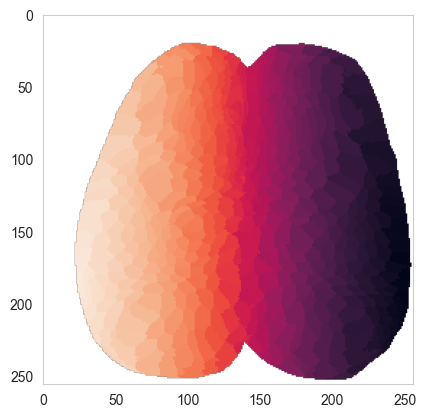

In [5]:
with h5py.File(step_0_root+mouse+'/idx_sorted_500_'+mouse+'.mat','r') as f_idx:

    IDX_sorted = np.array(f_idx['IDX_sorted']).T
    IDX_sorted = IDX_sorted.astype(float)
    IDX_sorted[IDX_sorted==0]='nan'
    num_regions = int(np.nanmax(IDX_sorted.reshape((-1,1))))
    props = regionprops(IDX_sorted.astype(int))
    node_coords = [props[i].centroid for i in range(len(props))]
    node_coords = np.asarray(node_coords, dtype=np.float32)
    
    mask = IDX_sorted >0
    mask = mask.astype(float)
    mask[mask==0]='nan'
    
plt.imshow(IDX_sorted)


In [7]:
# MM_jrgeco = np.empty((256,256,60,0))
# MM_gcamp = np.empty((256,256,60,0))

# MM_raw = {key:np.empty((256,256,60,0)) for key in ['green','lime','red','blue']}

# for i_bout in range(norm_M_jrgeco.shape[-1]): 
#     session_id = M_day_label[i_bout]
#     day = session_id.split(mouse+'_')[1].split('_')[0]
#     run_id = session_id.split(mouse+'_')[1].split('_')[1]

#     f3 = list(set(glob.glob(step_1_root+mouse+"/"+day+"/*"+run_id+"*.mat")))[0]
#     ind = int(M_ind[i_bout]/4)


#     with h5py.File(f3,'r') as f_H: 
#         m = f_H['m']
#         C = np.array(f_H['C']['jrgeco'])
#         S = np.array(f_H['S']['jrgeco'])[ind-15:ind+45,:]
#         # cut [-60,60] frames slice
#         # mask = np.array(f_H['mask'])
#         # nanidx = np.squeeze(~np.isnan(mask.reshape((1,-1))))
#         nanidx = np.squeeze(m['nanidx'])==1
#         CS = np.dot(S,C).transpose()
#         jrgeco = np.zeros((len(nanidx),CS.shape[-1]))
#         jrgeco[:] = np.nan
#         jrgeco[nanidx==True,:] = CS
#         jrgeco = jrgeco.reshape((256,256,-1)).transpose((1,0,2))

#         C = np.array(f_H['C']['gcamp'])
#         S = np.array(f_H['S']['gcamp'])[ind-15:ind+45,:]
#         # cut [-60,60] frames slice
#         CS = np.dot(S,C).transpose()
#         gcamp = np.zeros((len(nanidx),CS.shape[-1]))
#         gcamp[:] = np.nan
#         gcamp[nanidx==True,:] = CS
#         gcamp = gcamp.reshape((256,256,-1)).transpose((1,0,2))     
        
# #         for key in ['green','lime','red','blue']:
# #             C = np.array(f_H['C'][key])
# #             S = np.array(f_H['S'][key])[ind-15:ind+45,:]
# #             CS = np.dot(S,C).transpose()

# #             temp = CS
# #             temp = temp.reshape((256,256,-1)).transpose((1,0,2))     
            
# #             # temp_norm = temp-np.mean(temp[:,:,bsl],axis=-1)[:,:,np.newaxis]
# #             MM_raw[key] = np.append(MM_raw[key],temp[:,:,:,np.newaxis],axis=3)
            
#         # de-baseline too
#         # gcamp_norm = gcamp -np.mean(gcamp[:,:,bsl],axis=-1)[:,:,np.newaxis]
#         bsl = range(0,15)
#         for i_fluorofore,fluorophore in enumerate(['jrgeco','gcamp']):
#             exec("{}_norm = {}-np.mean({}[:,:,bsl],axis=-1)[:,:,np.newaxis]".format(fluorophore,fluorophore,fluorophore))
#         MM_jrgeco = np.append(MM_jrgeco,jrgeco_norm[:,:,:,np.newaxis],axis=3)
#         MM_gcamp = np.append(MM_gcamp,gcamp_norm[:,:,:,np.newaxis],axis=3)  
    
#     # print(MM_jrgeco.shape)

 

In [6]:
save_dict = load_pickle(load_root+mouse+'_MM_full_dict')
full_res_dict = save_dict['full_res_dict']
MM_jrgeco = full_res_dict['MM_jrgeco']
MM_gcamp = full_res_dict['MM_gcamp']

In [7]:
MM_jrgeco.shape

(256, 256, 60, 113)

In [8]:
save_dict['all_gather_dict'].keys()

dict_keys(['norm_M_jrgeco', 'norm_M_gcamp', 'norm_M_chbt', 'M_day_label', 'M_ind', 'norm_M_RFP_vel_norm', 'norm_M_face_pc', 'norm_M_body_pc', 'norm_M_mirrorRFP_vel_norm', 'norm_M_LFP_vel_norm', 'norm_M_rotf'])

In [9]:
save_dict['all_gather_dict']['norm_M_LFP_vel_norm'].shape

(60, 113)

**mask out midline**

In [10]:
with h5py.File(figure_config_root+'mask_midline_'+mouse+'.mat','r') as f_midline:
    mask_midline = np.array(f_midline['mask_midline']).T
    
# mask out midline
# mask_midline_array = np.repeat(mask_midline[:,:,np.newaxis],repeats=jrgeco_norm.shape[-1],axis=2)
MM_jrgeco = np.multiply(MM_jrgeco,mask_midline[:,:,np.newaxis,np.newaxis])
MM_gcamp = np.multiply(MM_gcamp,mask_midline[:,:,np.newaxis,np.newaxis])


In [11]:
# load colormap
fire_cmap = load_pickle(figure_config_root+'fire_cmap')
from matplotlib import cm
icefire = cm.get_cmap('icefire')
viridis = cm.get_cmap('viridis')

/var/folders/kd/ywhkc6v94gq46vrbg78rzh240000gq/T/ipykernel_62980/1968519638.py:4: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  icefire = cm.get_cmap('icefire')
/var/folders/kd/ywhkc6v94gq46vrbg78rzh240000gq/T/ipykernel_62980/1968519638.py:5: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  viridis = cm.get_cmap('viridis')


# ADD aggregated

In [12]:
AVG_jrgeco = np.mean(MM_jrgeco,-1)
AVG_gcamp = np.mean(MM_gcamp,-1)
H_gcamp = getH_4D(MM_gcamp,IDX_sorted)
H_jrgeco = getH_4D(MM_jrgeco,IDX_sorted)

/Volumes/WX/code/code_ncomms_revision/make_0_prepare/common-functions/f2_utils.py:28: RuntimeWarning: Mean of empty slice
  H[i_H,:,:]=np.nanmean(data_reshape[temp==True,:,:],axis=0)


In [13]:
avg_time_series = np.array([18,33])

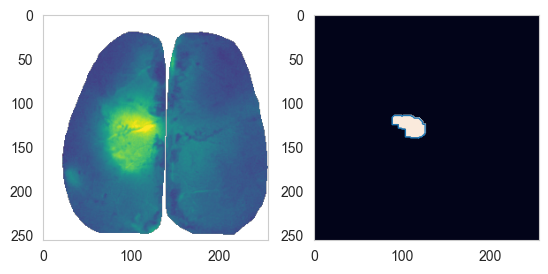

In [14]:
avg_clean_contours_series={}

plt.subplot(121)
plt.imshow(AVG_gcamp[:,:,avg_time_series[0]],vmax=0.06,cmap='viridis')
plt.subplot(122)
boolean_img = AVG_gcamp[:,:,avg_time_series[0]]>0.045

boolean_img = boolean_img.astype('int')
kernel = np.ones((9,9),np.uint8)
opening = cv2.morphologyEx(np.uint8(boolean_img), cv2.MORPH_OPEN, kernel)

contours = measure.find_contours(opening, 0.8)
clean_contours=[]
for i_contour,contour in enumerate(contours):
    if len(contour)<30:
        # print('place holder')
        a=1
    else:
        clean_contours.append(contours[i_contour])
            
plt.imshow(opening,vmax=0.06)
for contour in clean_contours:
    plt.plot(contour[:,1],contour[:,0],linewidth=1)

avg_clean_contours_series[0]={}
avg_clean_contours_series[0]['time_frame'] = avg_time_series[0]
avg_clean_contours_series[0]['clean_contours'] = clean_contours
avg_clean_contours_series[0]['threshold'] = 0.045


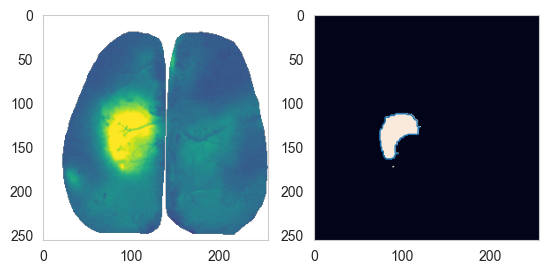

In [15]:
plt.subplot(121)
plt.imshow(AVG_gcamp[:,:,avg_time_series[1]],vmax=0.06,cmap='viridis')
plt.subplot(122)
boolean_img = AVG_gcamp[:,:,avg_time_series[1]]>0.06

boolean_img = boolean_img.astype('int')
kernel = np.ones((9,9),np.uint8)
# opening = cv2.morphologyEx(np.uint8(boolean_img), cv2.MORPH_OPEN, kernel)
opening = cv2.dilate(np.uint8(boolean_img), kernel)
# kernel = np.ones((4,4),np.uint8)
opening = cv2.erode(opening,kernel)


plt.imshow(opening,vmax=0.06)

contours = measure.find_contours(opening, 0.8)
clean_contours=[]
for i_contour,contour in enumerate(contours):
    if len(contour)<30:
        # print('place holder')
        a=1
    else:
        clean_contours.append(contours[i_contour])
            
plt.imshow(opening,vmax=0.06)
for contour in clean_contours:
    plt.plot(contour[:,1],contour[:,0],linewidth=1)


avg_clean_contours_series[1]={}
avg_clean_contours_series[1]['time_frame'] = avg_time_series[0]
avg_clean_contours_series[1]['clean_contours'] = clean_contours
avg_clean_contours_series[1]['threshold'] = 0.06

In [16]:
M_raw={}
t1 = 340
with h5py.File(step_1_root+'{}/{}/{}_stim_1.mat'.format(mouse,'3','runD'),'r') as f_H: 
    for key in ['green','lime','red','blue']:
        C = np.array(f_H['C'][key])
        S = np.array(f_H['S'][key])[t1:t1+1,:]
        CS = np.dot(S,C).transpose()

        temp = CS
        temp = temp.reshape((256,256,-1)).transpose((1,0,2))     

        # temp_norm = temp-np.mean(temp[:,:,bsl],axis=-1)[:,:,np.newaxis]
        M_raw[key] = temp


In [17]:
with h5py.File(figure_config_root+'mask_midline_'+mouse+'.mat','r') as f_midline:
    mask_midline = np.array(f_midline['mask_midline']).T
    
# mask out midline
mask_midline_array = np.repeat(mask_midline[:,:,np.newaxis],repeats=AVG_gcamp.shape[-1],axis=2)
AVG_jrgeco = np.multiply(AVG_jrgeco,mask_midline_array)
AVG_gcamp = np.multiply(AVG_gcamp,mask_midline_array)

mask_midline_array = np.repeat(mask_midline[:,:,np.newaxis],repeats=M_raw['lime'].shape[-1],axis=2)
M_raw['lime'] = np.multiply(M_raw['lime'],mask_midline_array)
M_raw['blue'] = np.multiply(M_raw['blue'],mask_midline_array)

In [18]:
fetch_path_M2 = str(PREPARES / "index-M2") + "/"
M2_ind  = load_pickle(fetch_path_M2+'brightest_frontline_ind-'+mouse)
new_choice_ind={}
new_choice_ind['M2']=M2_ind['RFP']
new_choice_ind['S1']=412 #sensory_ind['RFP']
new_choice_ind['M1']=322 # for CM229

In [19]:
# new_palatte_dict={}
# new_palatte_dict['S1']='#015EB5'
# new_palatte_dict['M2']='#6DAE96'  
# new_palatte_dict['M1']= '#C44B30'  

palatte_dict = load_pickle(figure_config_root+'palatte_dict')
palatte_dict['RFP_M2']='#6dae96'
palatte_dict['RFP_M1']='#4b0082'
from matplotlib import cm
viridis = cm.get_cmap('viridis')

/var/folders/kd/ywhkc6v94gq46vrbg78rzh240000gq/T/ipykernel_62980/3707149481.py:10: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  viridis = cm.get_cmap('viridis')


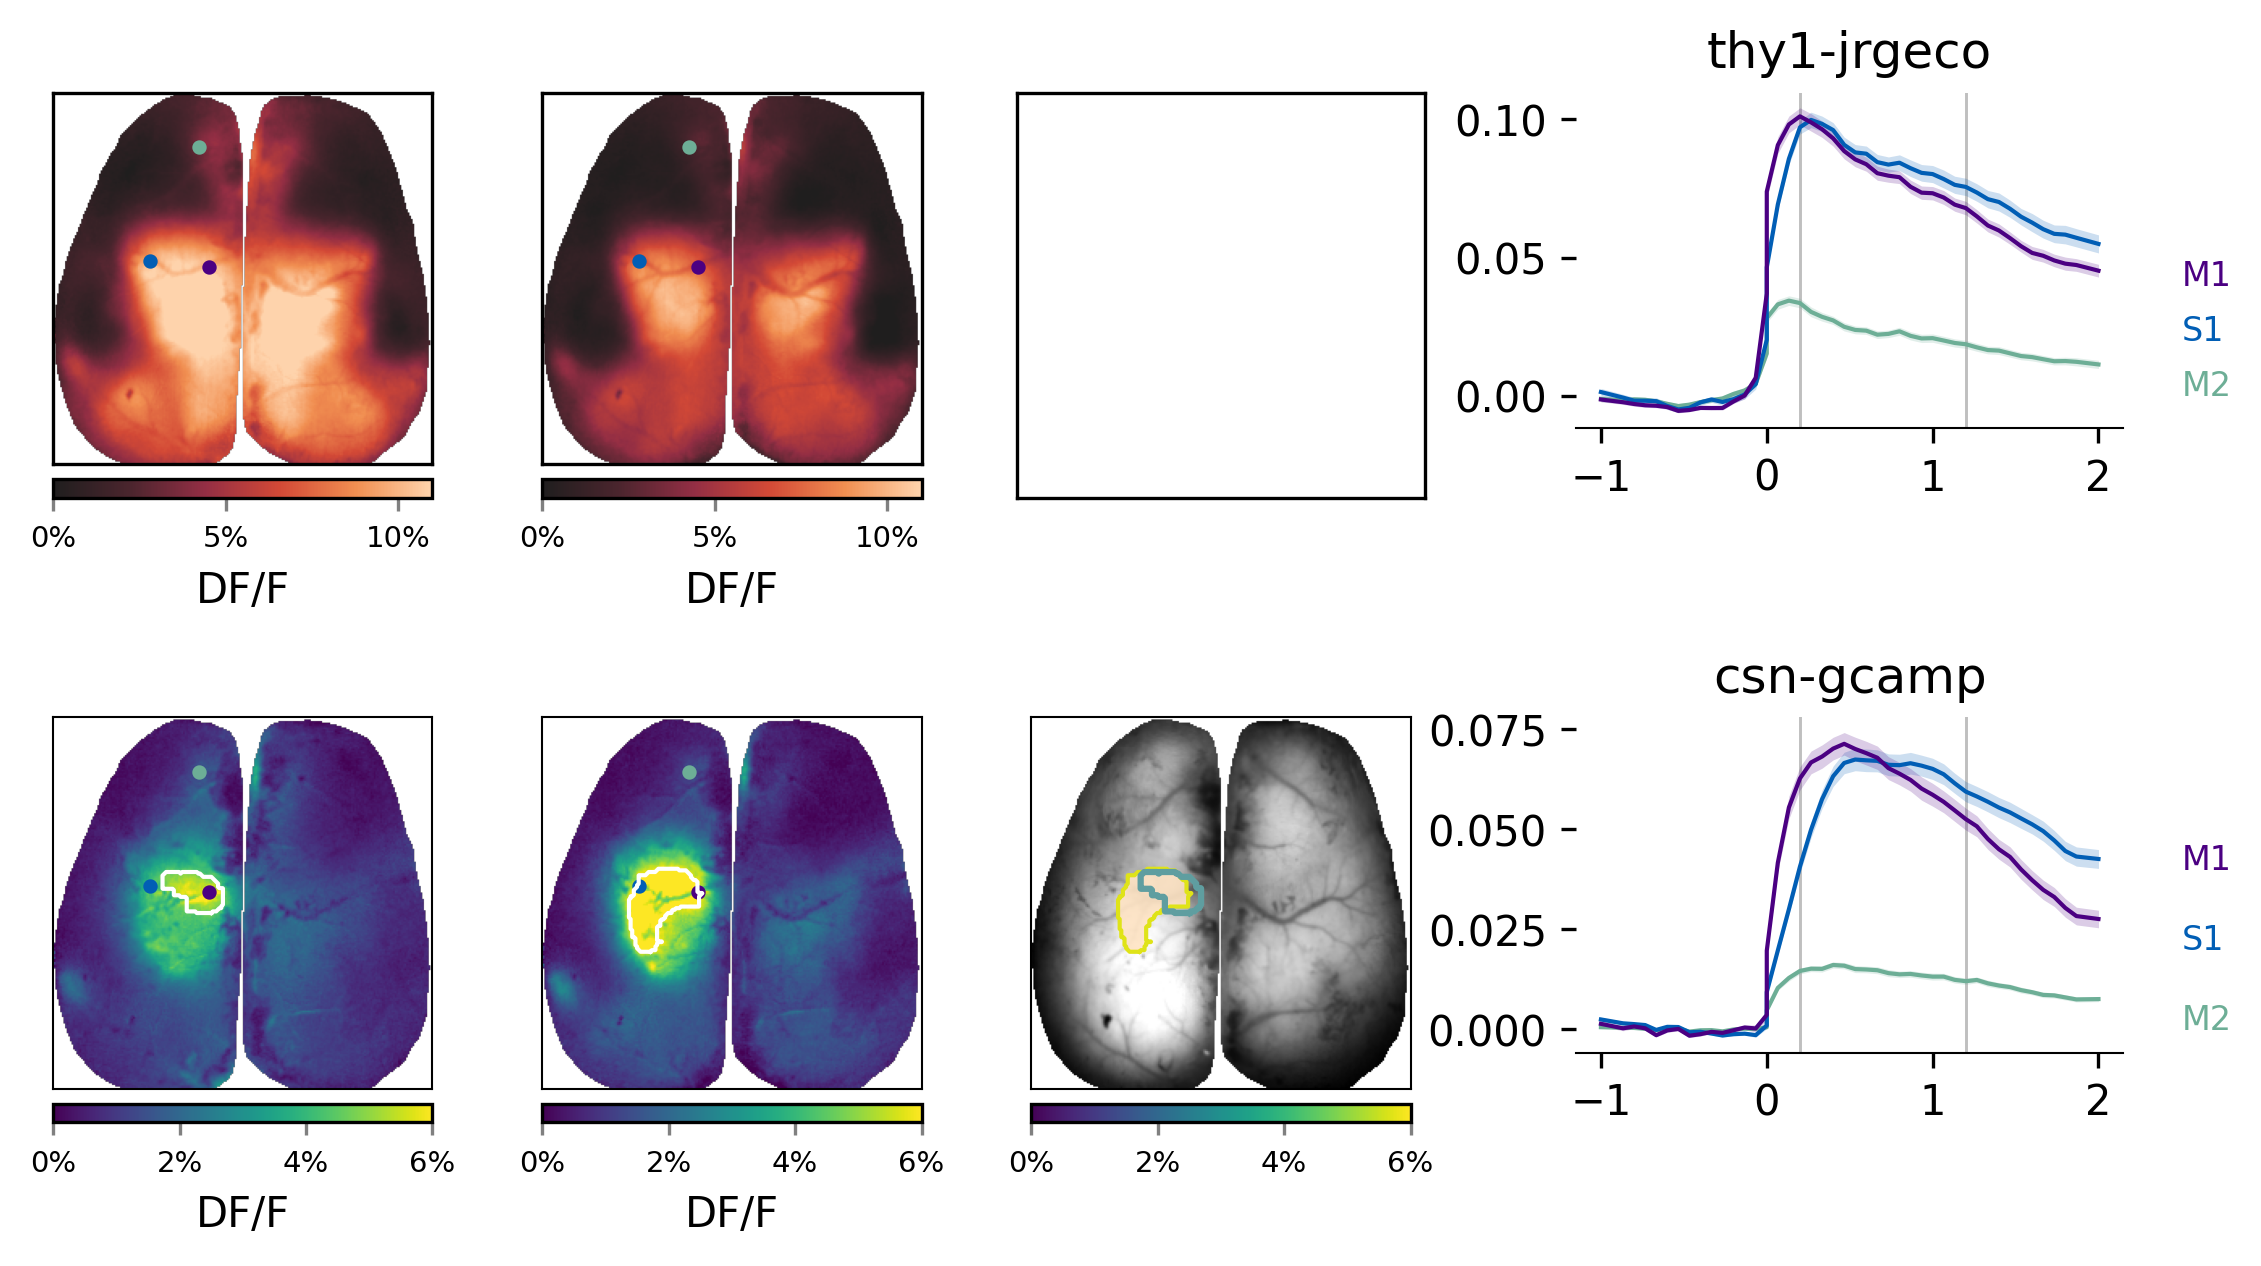

In [20]:
from skimage import measure
from matplotlib.gridspec import GridSpec
from skimage import measure
from matplotlib import ticker
import matplotlib
from matplotlib import ticker
from matplotlib.ticker import FuncFormatter
fmt = lambda x, pos: '{:.0%}'.format(x)
from mpl_toolkits.axes_grid1.axes_divider import make_axes_locatable

plt.style.use('default')
plt.rcParams['svg.fonttype'] = 'none'

gs = GridSpec(100,100)
# with plt.style.context(spstyle.get_style('nature')):
plt.rcParams['svg.fonttype'] = 'none'
fig = plt.figure(figsize=(30,30),dpi=300)

y_offset = 20;x_offset=20;y_gap=2;x_gap=2;x_width=6;y_gap=2;x_gap_four = 0;

y_start = y_offset 
y_stop = y_start+x_width
x_start = x_offset
x_stop = x_start + x_width
# CSN-GCAMP
for i_ax in range(0,3):
    exec("ax{} = fig.add_subplot(gs[y_start:y_stop,x_start:x_stop])".format(i_ax))
    x_start = x_stop+1 
    x_stop = x_start + x_width
    exec("ax{}.set_xticks([])".format(i_ax))
    exec("ax{}.set_yticks([])".format(i_ax))
    exec("ax{}.set_xlim([21,256]);ax{}.set_ylim([248,18])".format(i_ax,i_ax))

y_start = y_offset - 9
y_stop = y_start + x_width
x_start = x_offset
x_stop = x_start + x_width
# THY1-JRGECO
for i_ax in range(10,13):
    exec("ax{} = fig.add_subplot(gs[y_start:y_stop,x_start:x_stop])".format(i_ax))
    x_start = x_stop+1 
    x_stop = x_start + x_width
    exec("ax{}.set_xticks([])".format(i_ax))
    exec("ax{}.set_yticks([])".format(i_ax))
    exec("ax{}.set_xlim([21,256]);ax{}.set_ylim([248,18])".format(i_ax,i_ax))

# y_start = y_offset - 18
# y_stop = y_start+x_width
# x_start = x_offset
# x_stop = x_start + x_width
# # STD gcamp and jrgeco
# for i_ax in range(20,23):
#     exec("ax{} = fig.add_subplot(gs[y_start:y_stop,x_start:x_stop])".format(i_ax))
#     x_start = x_stop+1 
#     x_stop = x_start + x_width
#     exec("ax{}.set_xticks([])".format(i_ax))
#     exec("ax{}.set_yticks([])".format(i_ax))
#     exec("ax{}.set_xlim([21,256]);ax{}.set_ylim([248,18])".format(i_ax,i_ax))
    

x_start = x_offset+22
x_stop = x_start + 8
y_start = y_offset - 9
y_stop = y_start +5
for i_ax in range(3,5):
    exec("ax{} = fig.add_subplot(gs[y_start:y_stop,x_start:x_stop])".format(i_ax))
    y_start = y_stop+4
    y_stop = y_start + 5

# ax5 = fig.add_subplot(gs[y_start:y_stop+1,x_start:x_stop+1])
# ax5.set_aspect('equal', adjustable='box')
   
# CSN-GCAMP
for i_t,i_ax in enumerate(range(0,2)):
    if i_ax==0:
        exec("sbp{} = ax{}.imshow(AVG_gcamp[:,:,avg_time_series[i_t]],vmin=0,vmax=0.06,aspect='equal',cmap='viridis')".format(i_ax,i_ax))
    if i_ax==1:
        exec("sbp{} = ax{}.imshow(AVG_gcamp[:,:,avg_time_series[i_t]],vmin=0,vmax=0.06,aspect='equal',cmap='viridis')".format(i_ax,i_ax))

    exec("divider = make_axes_locatable(ax{})".format(i_ax))
    cax = divider.append_axes('bottom', size='5%', pad=0.05)
    exec("cb=fig.colorbar(sbp{}, cax=cax,orientation='horizontal',format=FuncFormatter(fmt))".format(i_ax))
    cb.ax.tick_params(labelsize=7,length=3,color='gray')
    cb.ax.set_xlabel('DF/F')
    
# THY1-JRGECO
for i_t,i_ax in enumerate(range(10,12)):
    if i_ax==10:
        exec("sbp{} = ax{}.imshow(AVG_jrgeco[:,:,avg_time_series[i_t]],vmin=0,vmax=0.11,aspect='equal',cmap=fire_cmap)".format(i_ax,i_ax))
    if i_ax==11:
        exec("sbp{} = ax{}.imshow(AVG_jrgeco[:,:,avg_time_series[i_t]],vmin=0,vmax=0.11,aspect='equal',cmap=fire_cmap)".format(i_ax,i_ax))

    exec("divider = make_axes_locatable(ax{})".format(i_ax))
    cax = divider.append_axes('bottom', size='5%', pad=0.05)
    exec("cb=fig.colorbar(sbp{}, cax=cax,orientation='horizontal',format=FuncFormatter(fmt))".format(i_ax))
    cb.ax.tick_params(labelsize=7,length=3,color='gray')
    cb.ax.set_xlabel('DF/F')
    
# STD THY1-JRGECO and CSN-GCAMP
# sbp20 = ax20.imshow(np.multiply(mask_midline,STD_jrgeco),vmin=0,vmax=0.05,cmap=fire_cmap,aspect='equal')
# sbp21 = ax21.imshow(np.multiply(mask_midline,STD_gcamp),vmin=0,vmax=0.037,cmap='viridis',aspect='equal')
# for i_ax in range(20,22):
#     exec("divider = make_axes_locatable(ax{})".format(i_ax))
#     cax = divider.append_axes('bottom', size='5%', pad=0.05)
#     exec("cb=fig.colorbar(sbp{}, cax=cax,orientation='horizontal',format=FuncFormatter(fmt))".format(i_ax))
#     cb.ax.tick_params(labelsize=7,length=3,color='gray')
#     cb.ax.set_xlabel('std')
    

    
ax2.imshow(np.multiply(np.squeeze(M_raw['lime']),mask),cmap='gray',vmax=2500,aspect='equal')
i_ax=2
exec("divider = make_axes_locatable(ax{})".format(i_ax))
cax = divider.append_axes('bottom', size='5%', pad=0.05)
cb=fig.colorbar(sbp0, cax=cax,orientation='horizontal',format=FuncFormatter(fmt))
cb.ax.tick_params(labelsize=7,length=3,color='gray')


t_stop=45
t_start = 15
t_frame = np.linspace(-15,30,45).astype('int')
t_ax = np.divide(t_frame,15)


new_palatte = ['#8F4834', '#306F5A' ,'#EACD41', 'indigo','#171E26','#6DAE96' , '#C44B30']

all_gathered_3 = {'norm_M_RFP_vel_norm':'FP(R) speed',
                  'norm_M_LFP_vel_norm':'FP(L) speed'}
    
# for i_beh,beh in enumerate(all_gathered_3):
#     exec("data2plot = {}[t_start:t_stop+t_start,:]".format(beh))
#     avg = np.mean(data2plot,axis=-1)
#     sem = stats.sem(data2plot,axis=-1)
     
#     ax3.plot(t_ax,avg+i_beh*0,color=palette1[i_beh],linewidth =1)
#     ax3.fill_between(t_ax,avg+i_beh*0 - sem,avg +i_beh*0+sem,linewidth =0,color=palette1[i_beh],alpha=0.2)
#     exec("ax3.text(t_ax[-1]-t_ax[0]-0.7,0.8*i_beh,all_gathered_3[beh],color=palette1[i_beh],fontsize=8)".format(beh))
    
    
    
for i_key,key in enumerate(new_choice_ind):
    ind = new_choice_ind[key]
    data2plot = H_jrgeco[ind,:t_stop,:]
    avg = np.mean(data2plot,axis=-1)
    sem = stats.sem(data2plot,axis=-1)
    ax3.plot(t_ax,avg,label=key,color=palatte_dict['RFP_'+key],linewidth =1)
    ax3.fill_between(t_ax,avg - sem,avg +sem,color=palatte_dict['RFP_'+key],linewidth =0,alpha=0.2)
    ax3.text(t_ax[-1]-t_ax[0]-0.5,0.02*i_key,key,color=palatte_dict['RFP_'+key],fontsize=8)
ax3.set_title('thy1-jrgeco')    

for i_key,key in enumerate(new_choice_ind):
    ind = new_choice_ind[key]
    data2plot = H_gcamp[ind,:t_stop,:]
    avg = np.mean(data2plot,axis=-1)
    sem = stats.sem(data2plot,axis=-1)
    ax4.plot(t_ax,avg,label=key,color=palatte_dict['RFP_'+key],linewidth =1)
    ax4.fill_between(t_ax,avg - sem,avg +sem,color=palatte_dict['RFP_'+key],linewidth =0,alpha=0.2)
    ax4.text(t_ax[-1]-t_ax[0]-0.5,0.02*i_key,key,color=palatte_dict['RFP_'+key],fontsize=8)
ax4.set_title('csn-gcamp')    

# # trajectory plot
# z = range(M1_bouts.shape[0])
# sbp5 = ax5.scatter(np.mean(M1_bouts,-1),np.mean(S1_bouts,-1), c=z, marker='.',s=10,cmap='viridis')
# ax5.plot(np.mean(M1_bouts,-1),np.mean(S1_bouts,-1),c='gray',alpha=0.3)
# ax5.set_xlim([-0.005,0.08])
# ax5.set_ylim([-0.005,0.08])

# i_ax=5
# exec("divider = make_axes_locatable(ax{})".format(i_ax))
# cax = divider.append_axes('right', size='5%', pad=0.05)
# cb=fig.colorbar(sbp5, cax=cax,orientation='vertical')
# cb.ax.tick_params(labelsize=7,length=3,color='gray')
# tick_locator = ticker.MaxNLocator(nbins=2)
# cb.locator = tick_locator
# cb.update_ticks()
      
    
    
for iax in np.array([0,1,10,11]):
    for i_key,key in enumerate(new_choice_ind):
        ind = new_choice_ind[key]
        exec("ax{}.scatter(node_coords[ind,1],node_coords[ind,0],s=6,color=palatte_dict['RFP_'+key])".format(iax))

        
# plot contours
S1_contours = avg_clean_contours_series[1]['clean_contours']
for contour in S1_contours:
    ax1.plot(contour[:,1],contour[:,0],linewidth=1,color='white')
    ax2.plot(contour[:,1],contour[:,0],linewidth=1,color=viridis(0.95))
    ROI_2_plot = contour_to_roi(np.ones((256,256)),contour)
    c_black= matplotlib.colors.colorConverter.to_rgba('bisque',alpha = 1)
    c_black1= matplotlib.colors.colorConverter.to_rgba('bisque',alpha = 0.95)
    c_white= matplotlib.colors.colorConverter.to_rgba('bisque',alpha = 0.9)
    cmap_rb = matplotlib.colors.LinearSegmentedColormap.from_list('rb_cmap',[c_white,c_black1,c_black],5120)
    ax2.imshow(ROI_2_plot,cmap=cmap_rb)
    
M1_contours = avg_clean_contours_series[0]['clean_contours']
for contour in M1_contours:
    ax0.plot(contour[:,1],contour[:,0],linewidth=1,color='white')
    ax2.plot(contour[:,1],contour[:,0],linewidth=1.5,color='cadetblue')




for i_part,part in enumerate(['top','bottom','left','right']):
    for i_ax in range(10):
        try:
            exec("ax{}.spines[part].set_linewidth(0.5) ".format(i_ax))
        except:
            continue  

for i_ax in range(3,5):
    for axis in ['top','right','left']:
        exec("ax{}.spines[axis].set_linewidth(0)".format(i_ax))
        exec("ax{}.spines[axis].set_color('black')".format(i_ax))
        
for i_t in range(2):
    for i_ax in range(3,5):
        exec("ax{}.axvline(t_ax[avg_time_series[i_t]],alpha=0.5,linewidth=0.7,zorder=0,color='gray');".format(i_ax))
  


plt.savefig('fig5-thy1-csn-aggregated.svg',format='svg',dpi=300)

Fig 5f-iv (RFP, forepaw, cm229) M1 vs S1 timing: statistic=687, p-value = 1.9810e-09, n = 113 bouts


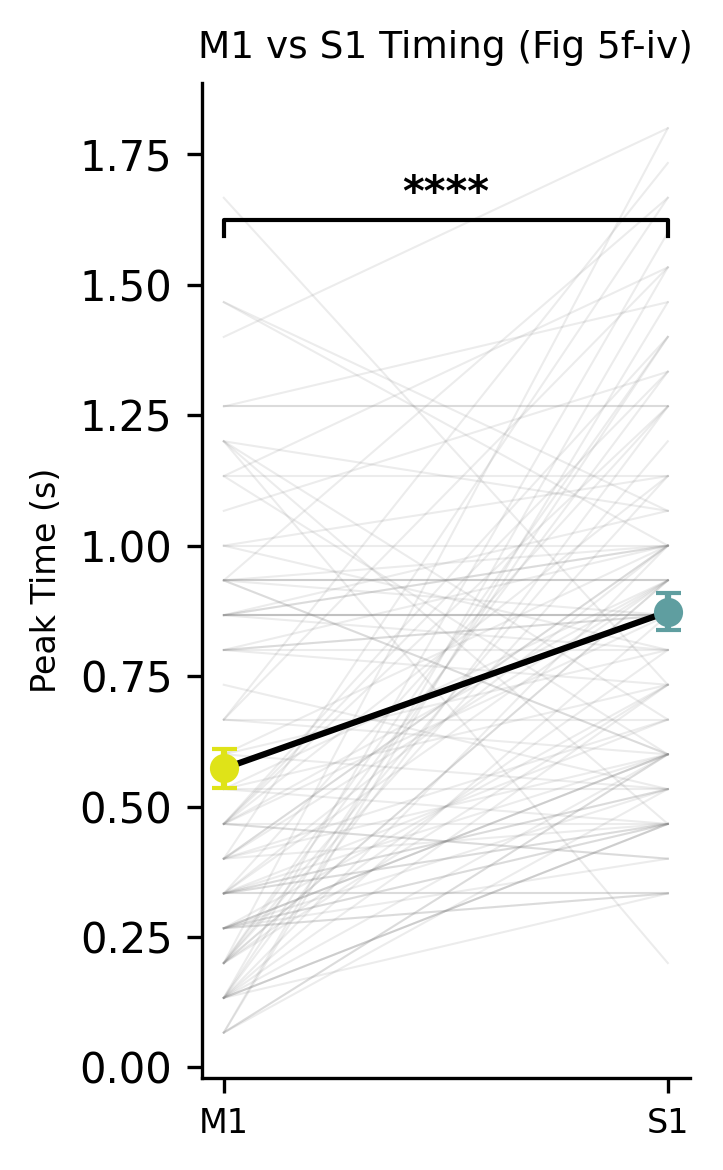

In [ ]:
# Fig 5f(iv): M1 vs S1 peak-timing statistics 
M1_bouts = H_gcamp[new_choice_ind['M1'], t_start:t_stop, :]
S1_bouts = H_gcamp[new_choice_ind['S1'], t_start:t_stop, :]

m1_peak_idx = np.argmax(M1_bouts, axis=0)
s1_peak_idx = np.argmax(S1_bouts, axis=0)
m1_peak_times = t_ax[t_start + m1_peak_idx]
s1_peak_times = t_ax[t_start + s1_peak_idx]

fig, ax7 = plt.subplots(figsize=(2.5, 4), dpi=300)
plt.rcParams['svg.fonttype'] = 'none'

for m, s in zip(m1_peak_times, s1_peak_times):
    ax7.plot([0, 1], [m, s], color='gray', alpha=0.15, linewidth=0.5, zorder=1)

s1_mean, s1_sem = np.mean(s1_peak_times), stats.sem(s1_peak_times)
m1_mean, m1_sem = np.mean(m1_peak_times), stats.sem(m1_peak_times)
ax7.errorbar(0, m1_mean, yerr=m1_sem, color=viridis(0.95), marker='o', markersize=6, capsize=3, zorder=2)
ax7.errorbar(1, s1_mean, yerr=s1_sem, color='cadetblue', marker='o', markersize=6, capsize=3, zorder=2)
ax7.plot([0, 1], [m1_mean, s1_mean], color='black', linewidth=1.5, zorder=2)

ax7.set_xticks([0, 1])
ax7.set_xticklabels(['M1', 'S1'], fontsize=8)
ax7.set_ylabel('Peak Time (s)', fontsize=8)
ax7.set_title('M1 vs S1 Timing (Fig 5f-iv)', fontsize=9)
for axis in ['top', 'right']:
    ax7.spines[axis].set_linewidth(0)

stat, p_val = stats.wilcoxon(m1_peak_times, s1_peak_times)
num_bouts = len(m1_peak_times)
print(f"Fig 5f-iv (RFP, forepaw, cm229) M1 vs S1 timing: statistic={stat:.4g}, "
      f"p-value = {p_val:.4e}, n = {num_bouts} bouts")

if p_val <= 0.0001:
    sig_star = '****'
elif p_val <= 0.001:
    sig_star = '***'
elif p_val <= 0.01:
    sig_star = '**'
elif p_val <= 0.05:
    sig_star = '*'
else:
    sig_star = 'ns'

y_max = np.max([s1_mean, m1_mean]) + 0.7
h_offset = 0.05
bracket_h = 0.02
ax7.plot([0, 0, 1, 1], [y_max + bracket_h, y_max + h_offset, y_max + h_offset, y_max + bracket_h],
         lw=1, c='black', zorder=3)
ax7.text(0.5, y_max + h_offset + 0.01, sig_star, ha='center', va='bottom', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.savefig('fig5f-iv-M1-vs-S1-timing.svg', format='svg', dpi=300)


# For revision

In [28]:
path_registration_file = str(PREPARES / "registration") + "/"
dict_transform = load_model(path_registration_file + 'dict_transform')

M = dict_transform[mouse]
M_2x3 = M[0:2, :]

def transform_contours(clean_contours, M_2x3):
    registered_contours = []
    for contour in clean_contours:
        pts = contour[:, ::-1]  # [y,x] -> [x,y]
        pts_h = np.hstack([pts, np.ones((pts.shape[0], 1))])
        transformed = (M_2x3 @ pts_h.T).T  # (N,2) in [x,y]
        registered_contours.append(transformed[:, ::-1])  # back to [y,x]
    return registered_contours

# Transform both time points
for key in avg_clean_contours_series:
    avg_clean_contours_series[key]['registered_contours'] = transform_contours(
        avg_clean_contours_series[key]['clean_contours'], M_2x3
    )

# Save to file for loading in the other notebook
save_path = str(FIGURES / "figure5") + "/"
with open(f'{save_path}{mouse}_registered_contours.pkl', 'wb') as f:
    pickle.dump(avg_clean_contours_series, f)